In [5]:
# allow us to re-use the framework from the src directory
import sys, os
sys.path.append(os.path.abspath(os.path.join('../')))

import pandas as pd
import matplotlib.gridspec as gridspec

import matplotlib.pyplot as plt
from matplotlib.backends.backend_agg import FigureCanvas

import max_ent.examples.grid_n_by_n as G
from max_ent.utility.support import *

from mc.mca import MCA
from mc.system1 import *
from max_ent.gridworld import Directions
from max_ent.algorithms.gridworld_icrl import Demonstration


In [6]:
'''n_cfg, c_cfg = G.generate_random_config(n_const=20, min_dist_start_goal=10, size=15)
n, c = n_cfg.mdp, c_cfg.mdp'''

'n_cfg, c_cfg = G.generate_random_config(n_const=20, min_dist_start_goal=10, size=15)\nn, c = n_cfg.mdp, c_cfg.mdp'

In [205]:
## Set the grid
blue = [21,  9, 59,  1,  0, 20]
green = [42, 18, 76, 41, 23, 30]
cs = [63, 74, 13, 39, 48, 38]
cc = [1, 2]
ca = [Directions.DOWN_LEFT, Directions.UP_LEFT, Directions.RIGHT, Directions.DOWN_RIGHT]
start =60
goal = 112
size = 15

n_grids = 3

n_trials = 30 #

n_trajectories = 1

bootstrap = 0
n_constraints = 50
n_actions = 2

threshold1 = 0 # 
threshold2 = 0.95 #0.95 # THIS REMOVE SECOND CONDITION
threshold3 = 0.9
list_threshold3 = [0.1, 0.3, 0.6, 0.9] # try with 0.9 or 1.0 / myopic and non-myopic S1
#list_threshold3 = [0.9,] # try with 0.9 or 1.0 / myopic and non-myopic S1
threshold4 = 0 # 

p_slip = 0.1

blue, green, cs, ca, _, _ = generate_constraints(size, n_constraints=n_constraints,goal = goal, action=n_actions)

In [4]:
n_cfg = G.config_world([], [], [], [], [], goal, start=start, size = size)
c_cfg = G.config_world(blue, green, cs, ca, cc, goal, start=start, size = size)
n, c = n_cfg.mdp, c_cfg.mdp
ca

[LEFT, UP]

{'vmin': -50.0, 'vmax': 10.0, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x7fa4df739438>}


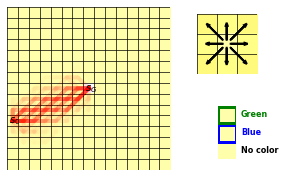

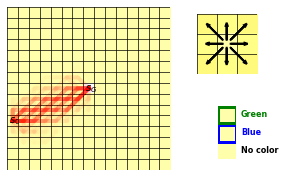

In [5]:
demo = G.generate_trajectories(n.world, n.reward, n.start, n.terminal)
vmin = c_cfg.state_penalties.min()
vmax = c_cfg.state_penalties.max()
G.plot_world('Nominal', n, n_cfg.state_penalties,
           n_cfg.action_penalties, n_cfg.color_penalties,
           demo, n_cfg.blue, n_cfg.green, vmin=vmin, vmax=vmax)


{'vmin': -50.0, 'vmax': 10.0, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x7fa4df739438>}


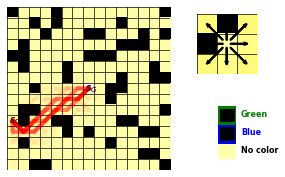

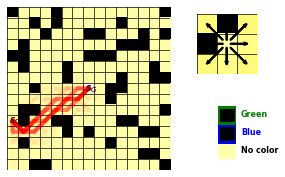

In [6]:
demo = G.generate_trajectories(c.world, c.reward, c.start, c.terminal)
vmin = c_cfg.state_penalties.min()
vmax = c_cfg.state_penalties.max()
G.plot_world('Nominal', c, c_cfg.state_penalties,
           c_cfg.action_penalties, c_cfg.color_penalties,
           demo, c_cfg.blue, c_cfg.green, vmin=vmin, vmax=vmax)


/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:356: RuntimeWarning: invalid value encountered in double_scalars
  x = np.abs(current_length - expected_avg_length) / max_diff_len
/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:169: RuntimeWarning: divide by zero encountered in double_scalars
  action_thresholds[1] = expected_avg_reward / current_reward


{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x7fa4df739438>}


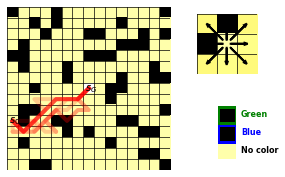

In [7]:
s1 = System1Solver(myopic=False, ra=0.75)
mca = MCA(n=n, c=c, s1=s1, demo=None, threshold1 = threshold1, threshold2 = threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5 = 1)
demo_mca = mca.generate_trajectories(10)

#mca = MCA(s1,s2,modelSelf, threshold1=threshold1, threshold2=threshold2, threshold3 = threshold3, threshold5 = threshold5, threshold7 = threshold7)
#print(c)
f1 = G.plot_world(f'MCA', c, c_cfg.state_penalties, 
              c_cfg.action_penalties, c_cfg.color_penalties, 
              demo_mca, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [206]:
demo_list = []
list_initial_state = [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,
                      15,30,45,60,75,90,105,120,135,150,165,180,195,210,
                      211,212,213,214,215,216,217,218,219,220,221,222,223,224,
                      14,29,44,59,74,89,104,119,134,149,164,179,194,209]

## Set the grid
blue = []
green = []
#cs = [21,  9, 59,  1,  0, 20, 42, 18, 76, 41, 23, 30, 63, 74, 13, 39, 48, 38]
#ca = [Directions.DOWN_LEFT, Directions.UP_LEFT, Directions.RIGHT, Directions.DOWN_RIGHT]
start = 0
goal = 112

n_cfg = G.config_world([], [], [], [], [], goal, start=start, size = size)
c_cfg = G.config_world(blue, green, cs, ca, cc, goal, start=start, size = size)
n, c = n_cfg.mdp, c_cfg.mdp

s1 = System1Solver(myopic=False, ra=1)
mca = MCA(n=n, c=c, s1=s1, demo=None, threshold1 = threshold1, threshold2 = threshold2, threshold3 = threshold3, threshold4 = threshold4, threshold5 = 1)

for trial in range(n_trials):
    print(f"================== TRIAL {trial} ==================")
    start = np.random.choice(np.setdiff1d(list_initial_state, cs))
    
    n_cfg = G.config_world([], [], [], [], [], goal, start=start, size = size)
    c_cfg = G.config_world(blue, green, cs, ca, cc, goal, start=start, size = size)
    n, c = n_cfg.mdp, c_cfg.mdp
    mca.setGrid(grid=n, constraints=c)
    demo = mca.generate_trajectories(n_trajectories, discard_not_feasable=False)
    demo_list = demo_list + demo.trajectories
    

================== TRIAL 0 ==================
================== TRIAL 1 ==================
================== TRIAL 2 ==================
================== TRIAL 3 ==================
================== TRIAL 4 ==================
================== TRIAL 5 ==================
================== TRIAL 6 ==================


/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:169: RuntimeWarning: divide by zero encountered in double_scalars
  action_thresholds[1] = expected_avg_reward / current_reward


================== TRIAL 7 ==================
================== TRIAL 8 ==================
================== TRIAL 9 ==================
================== TRIAL 10 ==================
================== TRIAL 11 ==================
================== TRIAL 12 ==================
================== TRIAL 13 ==================
================== TRIAL 14 ==================
================== TRIAL 15 ==================
================== TRIAL 16 ==================
================== TRIAL 17 ==================
================== TRIAL 18 ==================
================== TRIAL 19 ==================
================== TRIAL 20 ==================
================== TRIAL 21 ==================
================== TRIAL 22 ==================
================== TRIAL 23 ==================
================== TRIAL 24 ==================
================== TRIAL 25 ==================
================== TRIAL 26 ==================
================== TRIAL 27 ==================
================

{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x7fcdf8794630>}


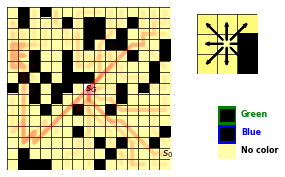

In [207]:
temp_demo = Demonstration(demo_list, demo.policy)
f1 = G.plot_world(f'MCA', c, c_cfg.state_penalties, 
              c_cfg.action_penalties, c_cfg.color_penalties, 
              temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

{'vmin': -50, 'vmax': 10, 'cmap': <matplotlib.colors.LinearSegmentedColormap object at 0x7f876573f320>}


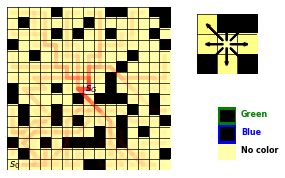

In [6]:
f1 = G.plot_world(f'MCA', c, c_cfg.state_penalties, 
              c_cfg.action_penalties, c_cfg.color_penalties, 
              temp_demo, c_cfg.blue, c_cfg.green, vmin=-50, vmax=10)

In [208]:
r = mca.reflect(1)
sum(r[3])

(0, 30)


/Users/aloreggia/Documents/GitHub/wmca/mc/mca.py:548: RuntimeWarning: invalid value encountered in double_scalars
  x = np.abs(current_length - expected_avg_length) / max_diff_len


9

In [218]:
values_new = []
values = []
delta = []
for i in range(len(r[1])):
    '''if r[3][i]:
        values_new.append((sum(r[1][i])))#/(len(r[1][i])*168)))
    else:
        values_new.append((sum(mca.action_reward[i])))#/sum(mca.time_stat[i])))'''
    values.append(-sum(mca.action_reward[i])*sum(mca.time_stat[i]))
    values_new.append(-sum(r[1][i])*sum(r[2][i]))
    delta.append(math.log(values[-1],size) - math.log(values_new[-1],size))
        

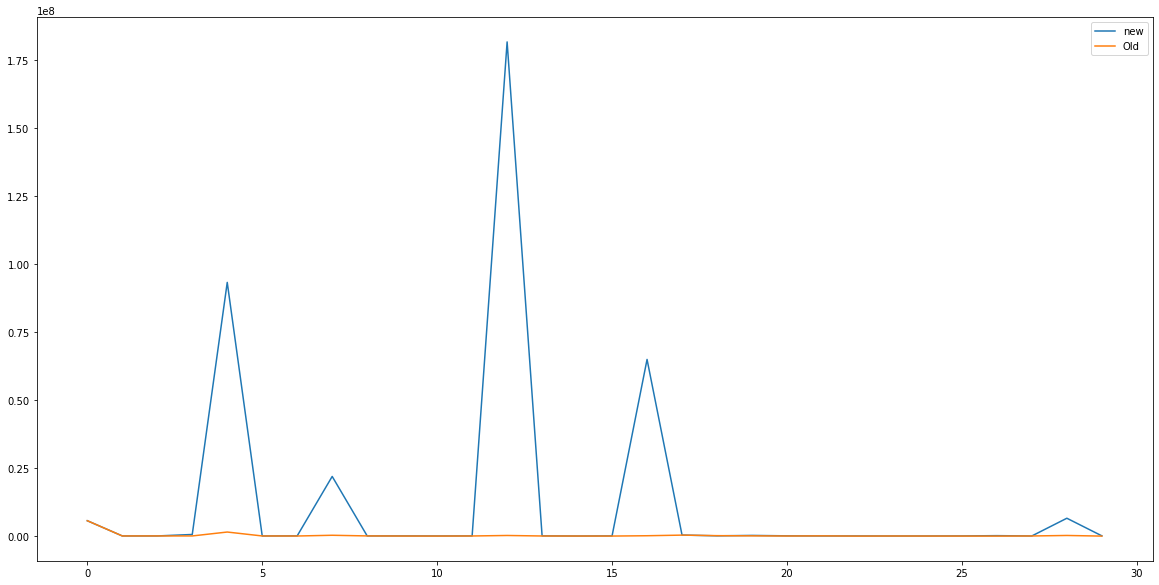

In [219]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_new, label="new")
plt.plot(values, label="Old")
plt.legend()

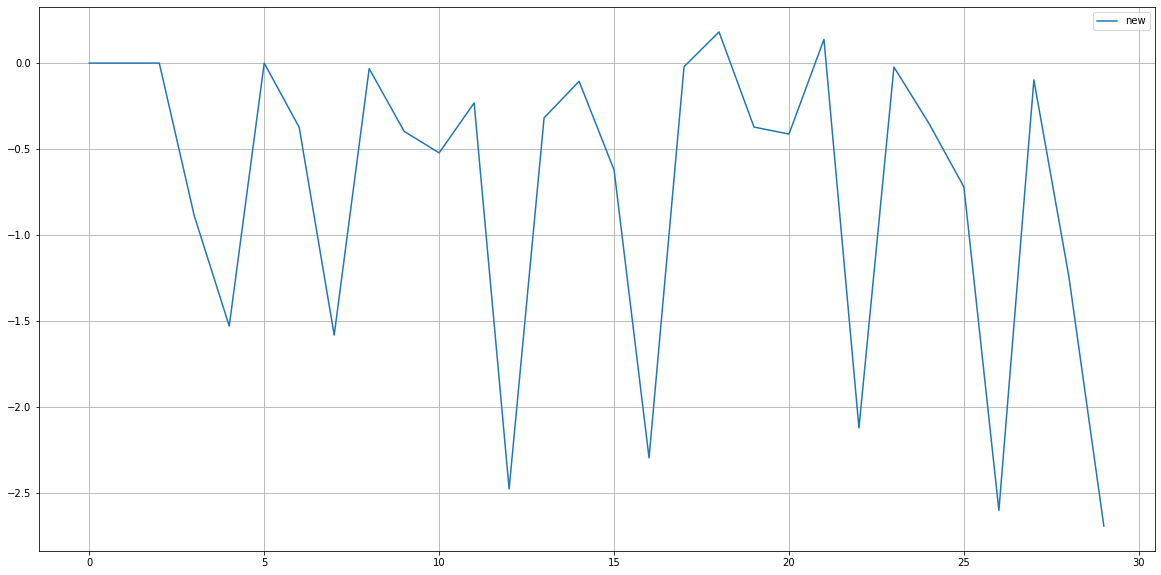

In [220]:
plt.figure(figsize=(20,10))
plt.grid(visible=True)
plt.plot(delta, label="new")
plt.legend()

In [221]:
values_reward = []
values_reward_new = []
for i in range(len(mca.action_reward)):
    values_reward.append(sum(mca.action_reward[i]))
    values_reward_new.append(sum(r[1][i]))

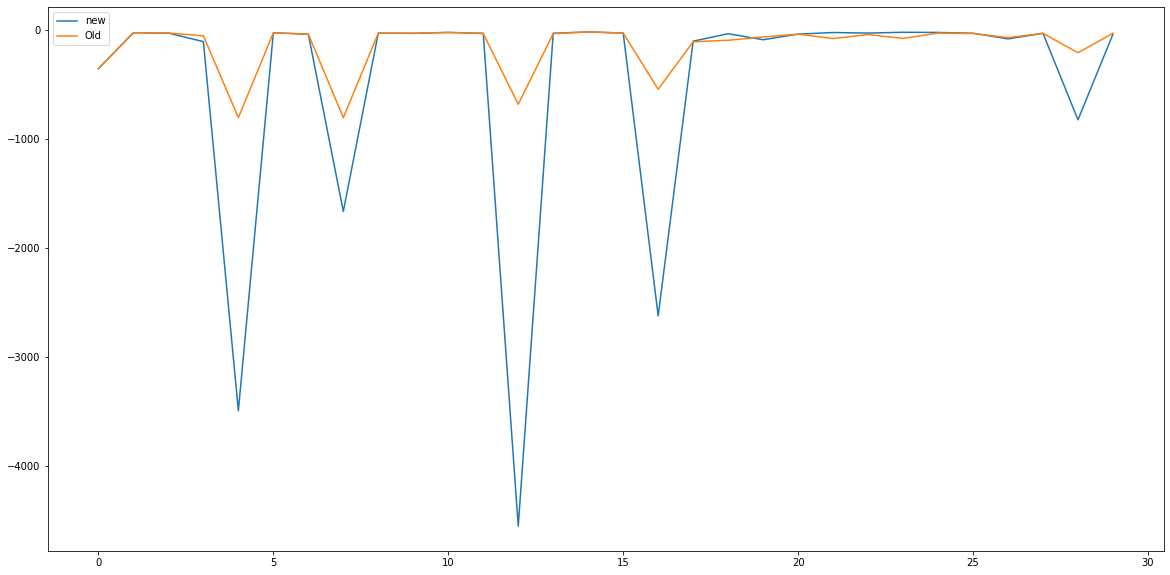

In [222]:
#New is over old, i.e. it is worst, because of the higher time taken to compute the new trajectory
plt.figure(figsize=(20,10))
plt.plot(values_reward_new, label="new")
plt.plot(values_reward, label="Old")
plt.legend()

In [223]:
np.where(np.array(r[3])==1)

(array([11, 13, 17, 18, 21, 22, 23, 24, 25]),)

In [224]:
len(np.where(np.array(delta)>-0.1)[0])

10

In [52]:
math.log(0.3)

-1.2039728043259361

In [59]:
values[-1],values_new[-1]

(71899.47701086901, 167692.34279737915)

In [66]:
len(np.where(np.array(delta)>= -0.2)[0])

17

In [301]:
epsilon = + 1E-4
origTraj = np.zeros((size * size, 8, size * size)) + epsilon

total = 0
for trajectory in mca.modelSelf.trajectories:
    total += len(trajectory.transitions())
    for transition in trajectory.transitions():
        origTraj[transition] += 1

In [302]:
newtraj = np.zeros((size * size, 8, size * size)) + epsilon

for trajectory in r[0]:
    for transition in trajectory:
        #print(f" newtraj[transition] {newtraj[transition]}  transition {tuple(transition)}")
        newtraj[tuple(transition)] += 1

In [272]:
#origTraj = origTraj / sum(np.reshape(origTraj, (-1,)))
#newtraj = newtraj / sum(np.reshape(newtraj, (-1,)))


In [273]:
np.reshape(origTraj, (-1,))

array([7.96812749e-07, 7.96812749e-07, 7.96812749e-07, ...,
       7.96812749e-07, 7.96812749e-07, 7.96812749e-07])

In [235]:
cross_entropy = 0
for i in range(len(np.reshape(newtraj, (-1,)))):
    p = np.reshape(newtraj, (-1,))[i]
    q = np.reshape(newtraj, (-1,))[i]
    cross_entropy += p * math.log(q,2)
    
print(f"Cross_entropy: {-cross_entropy}")
print(f"Perplexity: {math.pow(2,-cross_entropy)}")

Cross_entropy: 16.73405625880256
Perplexity: 109006.62237727066


In [179]:
sum(np.reshape(origTraj, (-1,)))

1.000000000014337

In [147]:
len(np.reshape(newtraj, (-1,)))

405000

In [237]:
def cross_entropy(p, q):
 return -sum([p[i]*math.log(q[i],2) for i in range(len(p))])


In [238]:
cross_entropy(np.reshape(newtraj, (-1,)),np.reshape(newtraj, (-1,)))

16.73405625880256

In [191]:
a = [0.5, 0.1, 0.1, 0.3]
cross_entropy(origTraj,origTraj)

TypeError: only size-1 arrays can be converted to Python scalars

In [204]:
len(mca.modelSelf.trajectories)

50

In [303]:
from scipy.spatial import distance
distance.jensenshannon(np.reshape(newtraj, (-1,)),np.reshape(origTraj, (-1,)))

0.6283122428789049

In [277]:
np.array(mca.modelSelf.trajectories)[np.where(np.array(r[4])==0)]

array([Trajectory([(195, 3, 181), (181, 3, 166), (166, 3, 150), (150, 0, 151), (151, 0, 150), (150, 2, 165), (165, 0, 181), (181, 3, 166), (166, 0, 165), (165, 0, 165), (165, 3, 150), (150, 3, 135), (135, 2, 150), (150, 0, 150), (150, 2, 165), (165, 0, 165), (165, 0, 165), (165, 3, 150), (150, 2, 165), (165, 3, 151), (151, 2, 166), (166, 0, 152), (152, 0, 151), (151, 0, 150), (150, 2, 165), (165, 3, 150), (150, 2, 165), (165, 3, 150), (150, 0, 150), (150, 0, 150), (150, 0, 150), (150, 2, 165), (165, 3, 181), (181, 0, 180), (180, 3, 165), (165, 0, 165), (165, 3, 150), (150, 2, 165), (165, 0, 165), (165, 3, 150), (150, 3, 135), (135, 2, 121), (121, 3, 106), (106, 3, 91), (91, 3, 76), (76, 3, 61), (61, 3, 46), (46, 3, 31), (31, 5, 47), (47, 5, 46), (46, 3, 31), (31, 5, 47), (47, 3, 32), (32, 5, 48), (48, 5, 63), (63, 3, 48), (48, 5, 64), (64, 5, 49), (49, 2, 64), (64, 5, 80), (80, 5, 96), (96, 5, 112)]),
       Trajectory([(104, 3, 89), (89, 0, 88), (88, 0, 87), (87, 0, 86), (86, 0, 85), 

In [283]:
np.array(r[0])[np.where(np.array(r[4])==0)][3]

/Users/aloreggia/anaconda3/lib/python3.7/site-packages/ipykernel_launcher.py:1: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  """Entry point for launching an IPython kernel.


[array([149,   4, 163]),
 array([163,   0, 177]),
 array([177,   0, 176]),
 array([176,   6, 160]),
 array([160,   6, 144]),
 array([144,   6, 128]),
 array([128,   6, 112])]

In [287]:
origTraj

array([[[0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        ...,
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001]],

       [[0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        ...,
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001]],

       [[0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        [0.0001, 0.0001, 0.0001, ..., 0.0001, 0.0001, 0.0001],
        ...,
        [0.0

In [294]:
newtraj

array([[[2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01],
        [2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01],
        [2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01],
        ...,
        [2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01],
        [2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01],
        [2.50001e+01, 2.50001e+01, 2.50001e+01, ..., 2.50001e+01,
         2.50001e+01, 2.50001e+01]],

       [[1.00000e-04, 1.00000e-04, 1.00000e-04, ..., 1.00000e-04,
         1.00000e-04, 1.00000e-04],
        [1.00000e-04, 1.00000e-04, 1.00000e-04, ..., 1.00000e-04,
         1.00000e-04, 1.00000e-04],
        [1.00000e-04, 1.00000e-04, 1.00000e-04, ..., 1.00000e-04,
         1.00000e-04, 1.00000e-04],
        ...,
        [1.00000e-04, 1.00000e-04, 1.00000e-04, ..., 1